# Corpus Statistics — PubMed Cell & Tissue Biology

Dr. Nam H. Le — drnamlabs.com, bunnyquant.com

Know the data before training on it. This notebook streams the fetched corpus
(`data/corpus/slice_*.jsonl.gz`) once and reports everything the next stages depend on:

- **Volume**: docs, estimated tokens → confirms the Chinchilla-optimal model size (stage 3).
- **Length distribution** → sets the pretraining context length.
- **Time coverage** → is the corpus dominated by old or recent science?
- **Vocabulary & domain terms** → motivates a domain BPE tokenizer (stage 1).
- **Duplicates / junk** → dedup is the cheapest quality win in pretraining.


In [1]:
import glob, gzip, json, os, random, re
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

CORPUS = r"C:\Users\namle\projects\LLMs_from_start\data\corpus"
files = sorted(glob.glob(os.path.join(CORPUS, "slice_*.jsonl.gz")))
print(f"{len(files)} slice files")

482 slice files


In [2]:
# One streaming pass: counters only, no full corpus in RAM.
SEED = 42  # project convention: ONE seed, always recorded, always 42
rng = random.Random(SEED)
n_docs = 0
pmids_seen, dup_pmids = set(), 0
word_counts = []            # abstract length in words
year_docs = Counter()       # docs per year (from slice filename midpoint)
vocab = Counter()           # lowercase word frequencies
samples = []                # reservoir sample of 10 abstracts
word_re = re.compile(r"[a-zA-Z][a-zA-Z\-']+")

for i, path in enumerate(files):
    name = os.path.basename(path)              # slice_YYYYMMDD_YYYYMMDD.jsonl.gz
    y0, y1 = int(name[6:10]), int(name[15:19])
    year = (y0 + y1) // 2
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            d = json.loads(line)
            n_docs += 1
            if d["pmid"] in pmids_seen: dup_pmids += 1
            else: pmids_seen.add(d["pmid"])
            words = word_re.findall(d["abstract"])
            word_counts.append(len(words))
            year_docs[year] += 1
            vocab.update(w.lower() for w in words)
            if len(samples) < 10: samples.append(d)
            elif rng.random() < 10 / n_docs: samples[rng.randrange(10)] = d
    if (i + 1) % 50 == 0: print(f"  {i+1}/{len(files)} files, {n_docs:,} docs")

word_counts = np.array(word_counts)
print(f"\ndocs: {n_docs:,}   duplicate PMIDs: {dup_pmids:,}")

  50/482 files, 308,876 docs


  100/482 files, 644,452 docs


  150/482 files, 1,009,275 docs


  200/482 files, 1,407,958 docs


  250/482 files, 1,694,201 docs


  300/482 files, 2,004,558 docs


  350/482 files, 2,311,531 docs


  400/482 files, 2,633,800 docs


  450/482 files, 2,981,986 docs



docs: 3,198,416   duplicate PMIDs: 0


In [3]:
# Volume → model size (Chinchilla: ~20 tokens per parameter)
est_tokens = int(word_counts.sum() * 1.3)   # BPE inflation factor ~1.3 for English
print(f"total words:        {word_counts.sum():,}")
print(f"est. BPE tokens:    {est_tokens:,}")
print(f"Chinchilla-optimal: ~{est_tokens // 20 / 1e6:.0f}M params")
print(f"words/doc: mean {word_counts.mean():.0f}, p50 {np.percentile(word_counts,50):.0f}, "
      f"p90 {np.percentile(word_counts,90):.0f}, p99 {np.percentile(word_counts,99):.0f}, max {word_counts.max()}")

total words:        616,016,010
est. BPE tokens:    800,820,813
Chinchilla-optimal: ~40M params
words/doc: mean 193, p50 193, p90 265, p99 368, max 1439


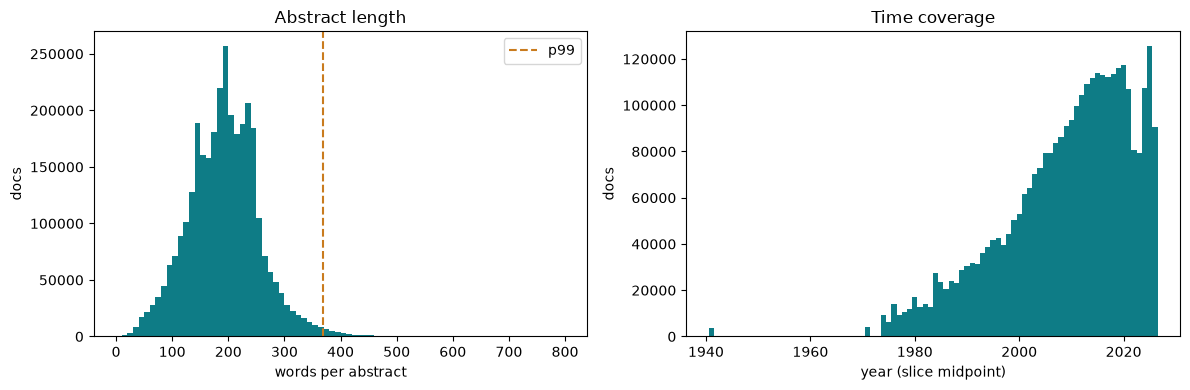

saved corpus_stats.png + corpus_summary.json -> C:\Users\namle\projects\LLMs_from_start\data\out


In [4]:
OUT_DIR = r"C:\Users\namle\projects\LLMs_from_start\data\out"
os.makedirs(OUT_DIR, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(word_counts, bins=80, range=(0, 800), color="#0E7C86")
axes[0].axvline(np.percentile(word_counts, 99), color="#C97B1E", ls="--", label="p99")
axes[0].set(xlabel="words per abstract", ylabel="docs", title="Abstract length")
axes[0].legend()
ys = sorted(year_docs)
axes[1].bar(ys, [year_docs[y] for y in ys], color="#0E7C86", width=1.0)
axes[1].set(xlabel="year (slice midpoint)", ylabel="docs", title="Time coverage")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "corpus_stats.png"), dpi=120)
plt.show()

# persist the headline numbers too — nothing exists unless it is saved
summary = {
    "seed": SEED, "date": "2026-10-22", "n_docs": int(n_docs),
    "dup_pmids": int(dup_pmids), "total_words": int(word_counts.sum()),
    "est_tokens": int(word_counts.sum() * 1.3),
    "words_per_doc": {"mean": float(word_counts.mean()),
                      "p50": float(np.percentile(word_counts, 50)),
                      "p90": float(np.percentile(word_counts, 90)),
                      "p99": float(np.percentile(word_counts, 99))},
    "unique_words": len(vocab),
}
with open(os.path.join(OUT_DIR, "corpus_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
print("saved corpus_stats.png + corpus_summary.json ->", OUT_DIR)

**Reading the length histogram**: p99 sets the context length for stage 3 — an abstract
that fits whole in the window is one coherent training example. If p99 ≈ 500 words
(~650 tokens), a 1024-token context covers title + abstract with room to spare.

In [5]:
# Domain-term coverage: does the corpus actually speak our language?
terms = ["membrane potential", "depolarization", "gap junction", "bioelectric",
         "morphogenesis", "regeneration", "ion channel", "voltage", "xenopus",
         "planarian", "tissue engineering", "stem cell", "apoptosis"]
single = {t: vocab[t] for t in terms if " " not in t}
print(f"unique lowercase words: {len(vocab):,}   (why word-level vocab is hopeless → BPE)")
print(f"hapax legomena (freq 1): {sum(1 for c in vocab.values() if c == 1):,}")
print("\nterm frequencies (single words):")
for t, c in sorted(single.items(), key=lambda kv: -kv[1]):
    print(f"  {t:20s} {c:>10,}  ({1e6*c/max(1,sum(word_counts)):.0f} per 1M words)")
print("\ntop 25 content words:")
stop = set("the of and in to a with for was were by on is that at from as this these are an or be".split())
print(", ".join(w for w, _ in vocab.most_common(200) if w not in stop)[:600])

unique lowercase words: 2,158,193   (why word-level vocab is hopeless → BPE)
hapax legomena (freq 1): 1,049,474

term frequencies (single words):
  apoptosis               803,565  (1304 per 1M words)


  regeneration            188,903  (307 per 1M words)


  depolarization           41,157  (67 per 1M words)
  voltage                  36,964  (60 per 1M words)
  morphogenesis            36,200  (59 per 1M words)
  xenopus                  24,584  (40 per 1M words)


  planarian                 1,527  (2 per 1M words)
  bioelectric               1,151  (2 per 1M words)

top 25 content words:
cells, cell, we, expression, which, not, study, have, protein, patients, after, activity, results, but, also, cancer, increased, treatment, both, effects, between, may, using, has, human, during, been, growth, levels, significantly, role, their, its, effect, than, can, signaling, it, mice, cd, our, group, potential, however, activation, showed, tumor, apoptosis, induced, used, into, analysis, response, development, gene, found, proliferation, compared, associated, no, control, pathway, function, two, through, vitro, model, studies, bone, receptor, significant, observed, more, different, tissue


In [6]:
# Eyeball two random abstracts — numbers never replace reading the data.
for d in samples[:2]:
    print(f"PMID {d['pmid']}: {d['title']}\n{d['abstract'][:500]}...\n{'-'*80}")

PMID 1710226: J1/tenascin in substrate-bound and soluble form displays contrary effects on neurite outgrowth.
The influence of J1/tenascin adsorbed to polyornithine-conditioned plastic (substrate-bound J1/tenascin) and J1/tenascin present in the culture medium (soluble J1/tenascin) on neurite outgrowth was studied with cultured single cells from hippocampus and mesencephalon of embryonic rats. Neurons at low density grew well on J1/tenascin substrates and extended neurites that were approximately 40% longer than on the polyornithine control substrate after 24 h in vitro. The neurite outgrowth promoting ...
--------------------------------------------------------------------------------
PMID 36281556: Identification of a novel prognostic signature correlated with epithelial-mesenchymal transition, N6-methyladenosine modification, and immune infiltration in colorectal cancer.
Colorectal cancer (CRC) is a commonly diagnosed human malignancy worldwide. Both epithelial-mesenchymal transitio

## Conclusions feeding the next stages

1. **Stage 1 (BPE)**: millions of unique words, a long hapax tail → word-level vocab is
   hopeless; byte-level BPE with a ~16k vocab trained on THIS corpus is the right tool.
2. **Stage 3 (pretrain)**: token count above fixes the model size by Chinchilla;
   p99 length fixes the context window.
3. **Dedup**: duplicate-PMID count above; near-duplicate abstracts (retractions,
   re-indexed records) worth a MinHash pass before training.
4. **Eval hygiene**: before stage 6, remove PubMedQA PMIDs from this corpus
   (contamination check is part of the release report).